In [15]:
import sys
import pandas as pd
from sqlalchemy import text

try:
    from prime.config import get_engine
except ModuleNotFoundError:
    raise ModuleNotFoundError(
        "Пакет prime не найден: ноутбук запущен не в окружении prime-monitor.\n"
        f"Сейчас Python отсюда: {sys.executable}\n"
        "JupyterLab: закройте его, перейдите в корень prime-monitor и выполните uv run jupyter lab.\n"
        "VS Code: Select Kernel справа сверху -> .venv из папки prime-monitor."
    ) from None

engine = get_engine()

def q(sql: str, **params) -> pd.DataFrame:
    try:
        with engine.connect() as conn:
            conn.execute(text("set time zone 'UTC'"))
            return pd.read_sql(text(sql), conn, params=params)
    finally:
        engine.dispose()

# задаем окно фактов
WINDOW = ("2026-01-01", "2026-07-01")

# выгружаем клиентов
clients = q("""
    select client_id, registered_at, region_code, acquisition_channel
    from prime.clients
""")

# выгружаем подписки
subscriptions = q("""
    select subscription_id, owner_client_id, tariff_id, started_at, ended_at
    from prime.subscriptions
""")

# выгружаем успешные платежи
payments = q("""
    select payment_id, subscription_id, paid_at, amount, status
    from prime.payments
    where paid_at >= :a and paid_at < :b
      and status = 'success'
""", a=WINDOW[0], b=WINDOW[1])

# выгружаем тикеты поддержки
support_tickets = q("""
    select ticket_id, client_id, category, created_at, resolved_at
    from prime.support_tickets
    where created_at >= :a and created_at < :b
""", a=WINDOW[0], b=WINDOW[1])

for name, frame in [("clients", clients), ("subscriptions", subscriptions), ("payments", payments), ("support_tickets", support_tickets)]:
    print(f"{name:<16} {len(frame):>9} строк")

print("\nКатегории в тикетах:", support_tickets['category'].unique())

clients             500000 строк
subscriptions       333905 строк
payments           1045826 строк
support_tickets      55084 строк

Категории в тикетах: <ArrowStringArray>
['кэшбэк', 'доступ к сервису', 'отмена подписки', 'шеринг', 'оплата',
 'прочее']
Length: 6, dtype: str


In [16]:
import numpy as np

# проверяем пропуски во всех загруженных таблицах
print("пропуски в данных", "\n")
for name, df in [("клиенты", clients), ("подписки", subscriptions), ("платежи", payments), ("тикеты", support_tickets)]:
    nulls = df.isna().sum().sum()
    print("таблица", name, nulls, "пропусков")

# считаем длительность решения тикета в часах
support_tickets['resolution_hours'] = (support_tickets['resolved_at'] - support_tickets['created_at']).dt.total_seconds() / 3600

# проверяем данные на баги и отрицательное время
print("\n", "статистика времени решения", support_tickets['resolution_hours'].describe())

anomalies = support_tickets[support_tickets['resolution_hours'] < 0]
print("тикетов с отрицательным временем решения", len(anomalies))

# группируем обращения по категориям
print("\n", "топ категорий обращений", support_tickets['category'].value_counts())

пропуски в данных 

таблица клиенты 10000 пропусков
таблица подписки 167978 пропусков
таблица платежи 0 пропусков
таблица тикеты 4415 пропусков

 статистика времени решения count    50669.000000
mean         8.195479
std         14.533341
min          0.100000
25%          1.790000
50%          4.010000
75%          9.020000
max        600.340000
Name: resolution_hours, dtype: float64
тикетов с отрицательным временем решения 0

 топ категорий обращений category
оплата              15062
доступ к сервису    11532
кэшбэк               8883
шеринг               7528
отмена подписки      7133
прочее               4946
Name: count, dtype: int64


In [17]:
# смотрим данные клиентов, пропуски и дубликаты
print("первые строки клиентов\n", clients.head())
print("пропуски в клиентах\n", clients.isna().sum())
print("дубликаты в клиентах", clients.duplicated().sum())

# изучаем подписки
print("\nпервые строки подписок\n", subscriptions.head())
print("пропуски в подписках\n", subscriptions.isna().sum())
print("дубликаты в подписках", subscriptions.duplicated().sum())

# анализируем платежи
print("\nпервые строки платежей\n", payments.head())
print("пропуски в платежах\n", payments.isna().sum())
print("дубликаты в платежах", payments.duplicated().sum())

# проверяем обращения в поддержку
print("\nпервые строки тикетов\n", support_tickets.head())
print("пропуски в тикетах\n", support_tickets.isna().sum())
print("дубликаты в тикетах", support_tickets.duplicated().sum())

первые строки клиентов
                               client_id             registered_at  \
0  d48a5eab-b6c6-470e-ba75-927f389a4d9c 2026-04-08 01:18:45+00:00   
1  48554854-4195-404f-9f67-d4b1eccae064 2024-06-27 07:10:15+00:00   
2  49ade004-ff93-40df-ac31-978ec17d5726 2024-02-01 21:38:41+00:00   
3  7aa2d30a-5be5-45b2-baea-ea5e28c0d96f 2025-09-16 15:42:41+00:00   
4  759e5c04-d5b4-4f24-bff9-c10878ffe361 2024-12-25 09:01:20+00:00   

   region_code acquisition_channel  
0           89     partner_telecom  
1           24             organic  
2            6     partner_telecom  
3           32              social  
4           69             organic  
пропуски в клиентах
 client_id                  0
registered_at              0
region_code                0
acquisition_channel    10000
dtype: int64
дубликаты в клиентах 0

первые строки подписок
                         subscription_id                       owner_client_id  \
0  8897bd51-4c14-425e-a5cd-ed7b4ab6a750  0e3ca737-e6e9-41f7-

In [18]:
# заполняем неизвестные каналы привлечения
clients['acquisition_channel'] = clients['acquisition_channel'].fillna('unknown')

# убираем открытые обращения и сортируем по времени создания
tickets_closed = support_tickets.dropna(subset=['resolution_hours']).sort_values('created_at')

# оставляем только отмененные подписки и сортируем по дате отмены
subs_canceled = subscriptions.dropna(subset=['ended_at']).sort_values('ended_at')

In [19]:
# присоединяем к каждому тикету ближайшую будущую отмену подписки этого же клиента
churn_df = pd.merge_asof(
    tickets_closed,
    subs_canceled,
    left_on='created_at',
    right_on='ended_at',
    left_by='client_id',
    right_by='owner_client_id',
    direction='forward'
)

# считаем сколько дней прошло от тикета до отмены
churn_df['days_to_churn'] = (churn_df['ended_at'] - churn_df['created_at']).dt.total_seconds() / (24 * 3600)

# 1, если клиент отменил подписку в течение 7 дней
churn_df['is_churned_7d'] = (churn_df['days_to_churn'] <= 7).astype(int)

# считаем среднюю конверсию в отток
churn_rate = churn_df['is_churned_7d'].mean() * 100
print("общий процент оттока в первую неделю после обращения", churn_rate)

общий процент оттока в первую неделю после обращения 0.39274507095067984


In [21]:
# считаем процент оттока для каждой категории тикета
churn_by_category = churn_df.groupby('category')['is_churned_7d'].mean() * 100
print("процент оттока по категориям\n", churn_by_category)

процент оттока по категориям
 category
доступ к сервису    0.423131
кэшбэк              0.539679
оплата              0.363108
отмена подписки     0.333384
прочее              0.393443
шеринг              0.288309
Name: is_churned_7d, dtype: float64


In [22]:
# разбиваем время решения на удобные интервалы
bins = [0, 2, 6, 12, 24, 1000]
labels = ['до 2ч', '2-6ч', '6-12ч', '12-24ч', 'более 24ч']
churn_df['sla_bucket'] = pd.cut(churn_df['resolution_hours'], bins=bins, labels=labels)

# считаем отток в зависимости от времени ожидания ответа
churn_by_sla = churn_df.groupby('sla_bucket')['is_churned_7d'].mean() * 100
print("процент оттока по времени ожидания\n", churn_by_sla)

процент оттока по времени ожидания
 sla_bucket
до 2ч        0.356444
2-6ч         0.401902
6-12ч        0.376058
12-24ч       0.388144
более 24ч    0.550087
Name: is_churned_7d, dtype: float64


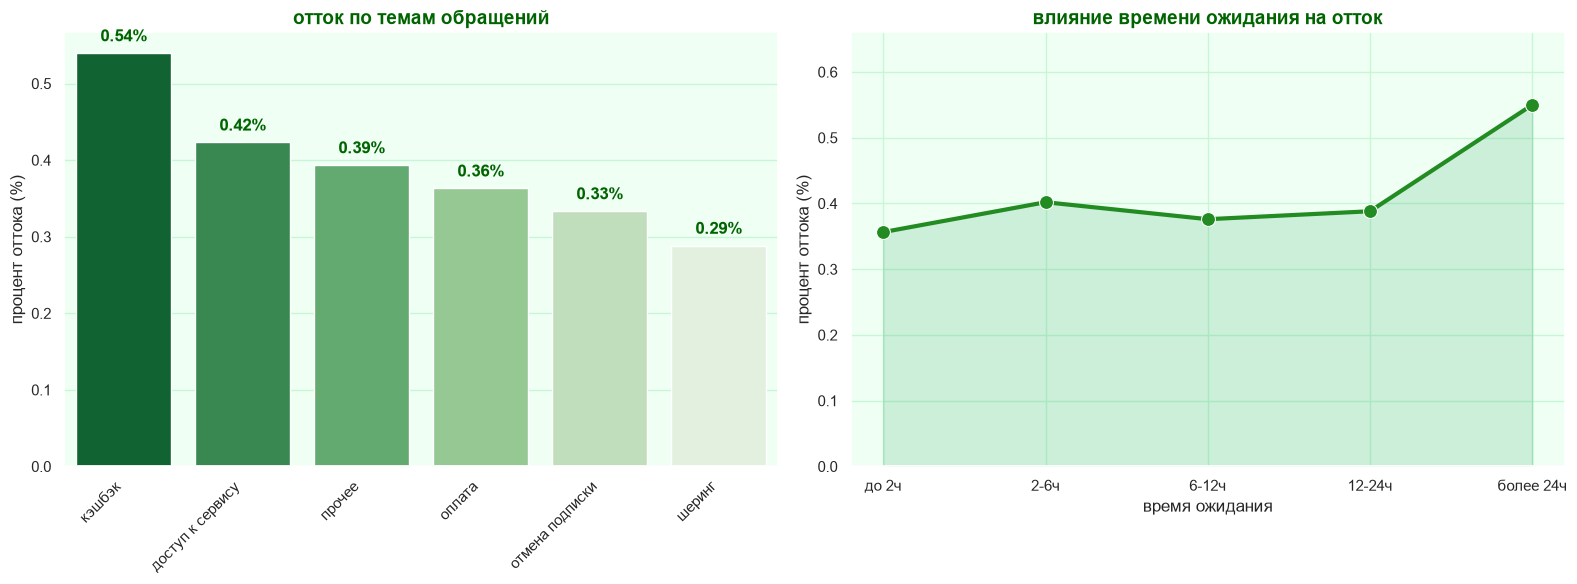

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid", rc={"axes.facecolor": "#f0fff4", "grid.color": "#c6f6d5"})
plt.figure(figsize=(16, 6))

#категории по убыванию оттока для наглядности
churn_by_category_sorted = churn_by_category.sort_values(ascending=False)

#диаграмма по категориям
plt.subplot(1, 2, 1)
ax1 = sns.barplot(
    x=churn_by_category_sorted.index,
    y=churn_by_category_sorted.values,
    hue=churn_by_category_sorted.index,
    legend=False,
    palette="Greens_r"
)
plt.title("отток по темам обращений", fontsize=14, fontweight='bold', color='darkgreen')
plt.ylabel("процент оттока (%)", fontsize=12)
plt.xlabel("")
plt.xticks(rotation=45, ha='right')

#добавление цифр над каждым столбцом
for p in ax1.patches:
    ax1.annotate(f'{p.get_height():.2f}%',
                 (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom',
                 xytext=(0, 6), textcoords='offset points',
                 color='darkgreen', fontweight='bold')

#линейный график по времени ожидания
plt.subplot(1, 2, 2)
ax2 = sns.lineplot(
    x=churn_by_sla.index,
    y=churn_by_sla.values,
    marker="o",
    markersize=10,
    color="forestgreen",
    linewidth=3
)

#заливка области под графиком для объема
plt.fill_between(
    x=range(len(churn_by_sla.index)),
    y1=churn_by_sla.values,
    y2=0,
    color="mediumseagreen",
    alpha=0.2
)

plt.title("влияние времени ожидания на отток", fontsize=14, fontweight='bold', color='darkgreen')
plt.ylabel("процент оттока (%)", fontsize=12)
plt.xlabel("время ожидания", fontsize=12)
plt.ylim(0, churn_by_sla.max() * 1.2)

plt.tight_layout()
plt.show()